<a href="https://colab.research.google.com/github/smir-nat/IAD-Practicals/blob/main/lab3/lab_3_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завдання 1

Epoch [10/50] | Train Loss: 1.1893 | Val Loss: 1.1547
Epoch [20/50] | Train Loss: 1.1774 | Val Loss: 1.1667
Epoch [30/50] | Train Loss: 1.1586 | Val Loss: 1.1569
Epoch [40/50] | Train Loss: 1.1433 | Val Loss: 1.1542
Epoch [50/50] | Train Loss: 1.1336 | Val Loss: 1.1506


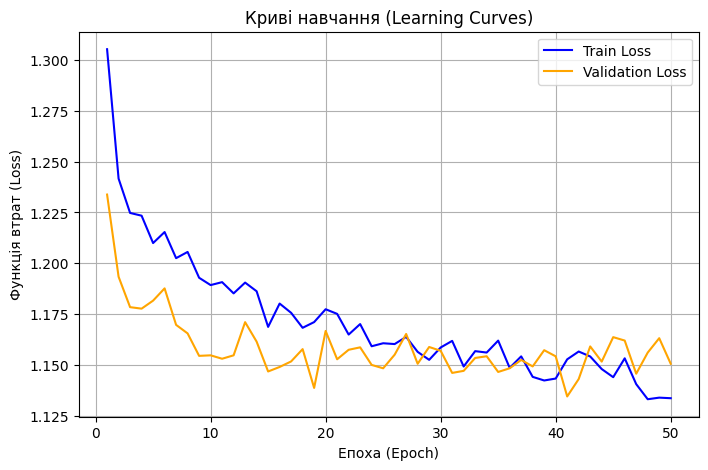


--- Результати класифікації (MLP PyTorch) ---
              precision    recall  f1-score   support

           0       0.98      0.69      0.81      1920
           1       0.08      0.65      0.14        80

    accuracy                           0.69      2000
   macro avg       0.53      0.67      0.48      2000
weighted avg       0.94      0.69      0.78      2000



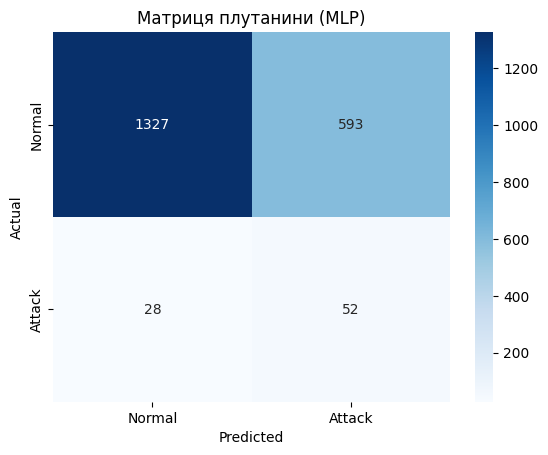

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

url = 'https://raw.githubusercontent.com/smir-nat/IAD-Practicals/main/lab2/cybersecurity.csv'
df = pd.read_csv(url)

cols_to_drop = ['timestamp', 'src_ip', 'dst_ip', 'url', 'attack_type']
df_clean = df.drop(columns=cols_to_drop)

le = LabelEncoder()
df_clean['protocol'] = le.fit_transform(df_clean['protocol'])
df_clean['user_agent'] = le.fit_transform(df_clean['user_agent'])
df_clean['is_internal_traffic'] = df_clean['is_internal_traffic'].astype(int)

X = df_clean.drop(columns=['label']).values
y = df_clean['label'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.FloatTensor(X_train_scaled)
y_train_t = torch.FloatTensor(y_train).view(-1, 1)
X_test_t = torch.FloatTensor(X_test_scaled)
y_test_t = torch.FloatTensor(y_test).view(-1, 1)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = TensorDataset(X_test_t, y_test_t)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

class MLP(nn.Module):
    def __init__(self, input_dim):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = MLP(input_dim=X_train.shape[1])

num_pos = y_train.sum()
num_neg = len(y_train) - num_pos
pos_weight = torch.tensor([num_neg / num_pos])

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    epoch_train_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item()
    train_losses.append(epoch_train_loss / len(train_loader))

    model.eval()
    epoch_val_loss = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            epoch_val_loss += loss.item()
    val_losses.append(epoch_val_loss / len(test_loader))

    if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs+1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, epochs+1), val_losses, label='Validation Loss', color='orange')
plt.title('Криві навчання (Learning Curves)')
plt.xlabel('Епоха (Epoch)')
plt.ylabel('Функція втрат (Loss)')
plt.legend()
plt.grid(True)
plt.show()

model.eval()
with torch.no_grad():
    y_pred_logits = model(X_test_t)
    y_pred = (torch.sigmoid(y_pred_logits) >= 0.5).float().numpy()

print("\n--- Результати класифікації (MLP PyTorch) ---")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title('Матриця плутанини (MLP)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Завдання 2

Завдання 3